# Grafieken in R (deel 2)
We gaan verder met de verschillende grafiektypen. Voor een overzicht van alle mogelijke grafiektypen: https://exts.ggplot2.tidyverse.org/gallery/

Een 'cheat'-sheet voor de ggplot2 grafiektypen staat hier:<br> https://ggplot2.tidyverse.org/

Voordat we beginnen: eerst de benodigde pakketten en libraries installeren en inlezen:

In [1]:
install.packages("tidyverse")

Installing package into ‘/usr/local/lib/R/site-library’
(as ‘lib’ is unspecified)



In [2]:
library(tidyverse)

── Attaching core tidyverse packages ──────────────────────── tidyverse 2.0.0 ──
✔ dplyr     1.1.4     ✔ readr     2.1.6
✔ forcats   1.0.1     ✔ stringr   1.6.0
✔ ggplot2   4.0.1     ✔ tibble    3.3.0
✔ lubridate 1.9.4     ✔ tidyr     1.3.1
✔ purrr     1.2.0     
── Conflicts ────────────────────────────────────────── tidyverse_conflicts() ──
✖ dplyr::filter() masks stats::filter()
✖ dplyr::lag()    masks stats::lag()
ℹ Use the conflicted package (<http://conflicted.r-lib.org/>) to force all conflicts to become errors


In [ ]:
install.packages("palmerpenguins")
install.packages("ggthemes")

library(palmerpenguins)
library(ggthemes)

Installing package into ‘/usr/local/lib/R/site-library’
(as ‘lib’ is unspecified)

Installing package into ‘/usr/local/lib/R/site-library’
(as ‘lib’ is unspecified)



Als voorbeeld bij de grafiektypen gebruiken we wederom de pinguins-dataset (penguins).

## geom_point
Een spreidingsdiagram of 'scatterplot' is een van de meest voorkomende grafiektypen voor het 'visualiseren' van een (mogelijke) relatie tussen 2 variabelen (zie ook les 1).

Warning message:
“Removed 2 rows containing missing values or values outside the scale range
(`geom_point()`).”


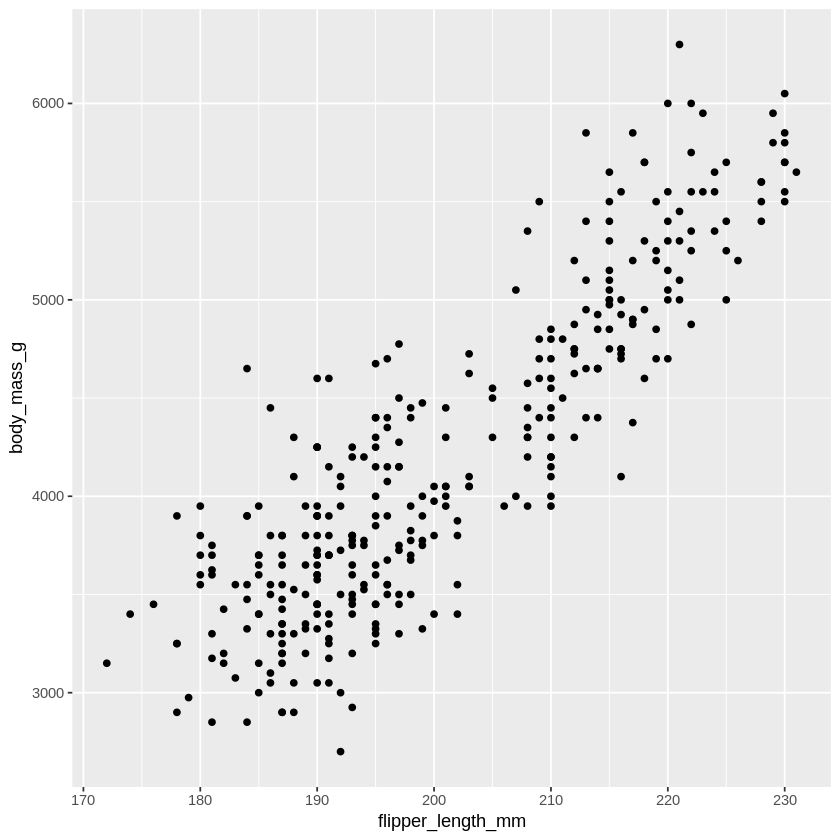

In [ ]:
ggplot(penguins, aes(x = flipper_length_mm, y = body_mass_g)) +
  geom_point()

Hetzelfde grafiektype, maar dan met 3 of meer variabelen (met behulp van color en shape) kan ook:

Warning message:
“Removed 2 rows containing missing values or values outside the scale range
(`geom_point()`).”


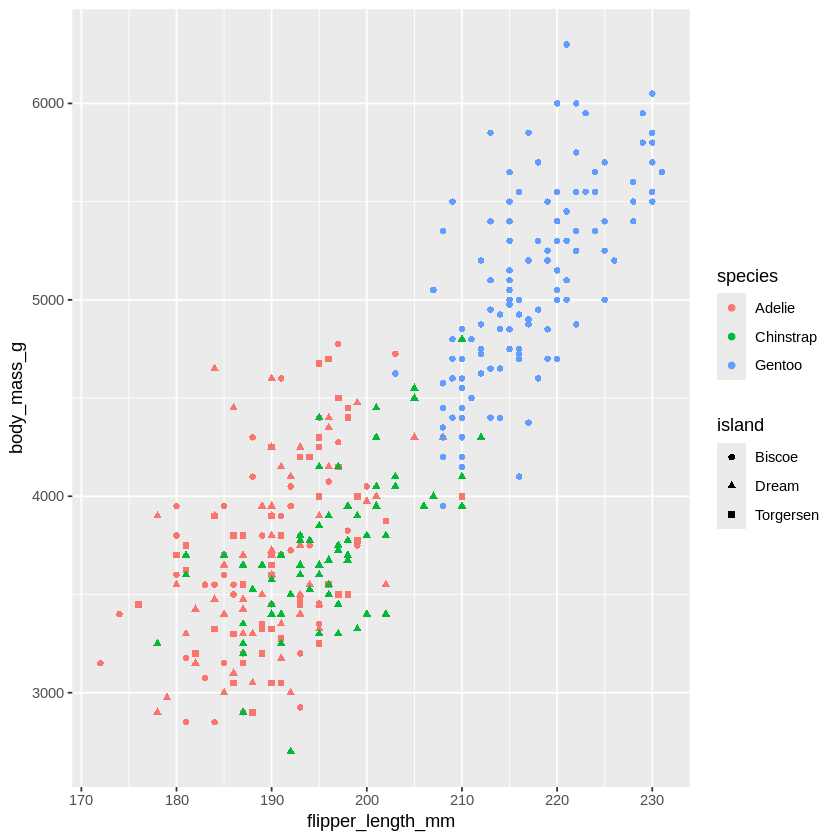

In [ ]:
ggplot(penguins, aes(x = flipper_length_mm, y = body_mass_g)) +
  geom_point(aes(color = species, shape = island))

Bovenstaande grafiek bevat wel erg veel informatie, misschien beter om dit in drie losse grafieken te laten zien met behulp van 'facet wrap':

Warning message:
“Removed 2 rows containing missing values or values outside the scale range
(`geom_point()`).”


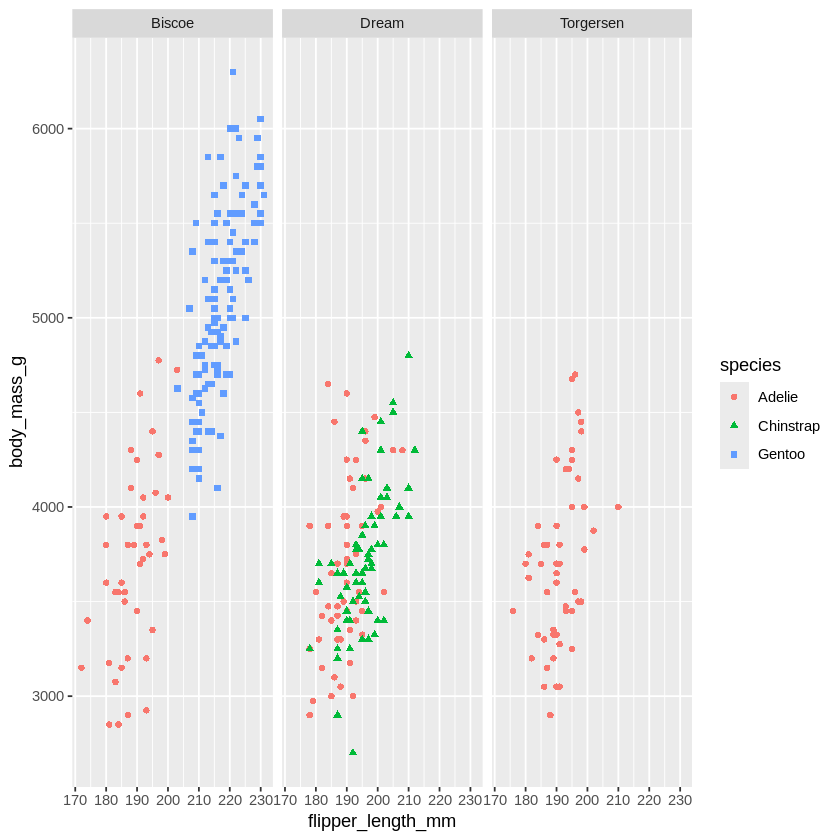

In [ ]:
ggplot(penguins, aes(x = flipper_length_mm, y = body_mass_g)) +
  geom_point(aes(color = species, shape = species)) +
  facet_wrap(~island)

## geom_bar
Een veelgebruikt grafiektype is het staafdiagram.<br>
We beginnen met een staafdiagram met op de x-as de soort (species) en op de y-as het aantal:

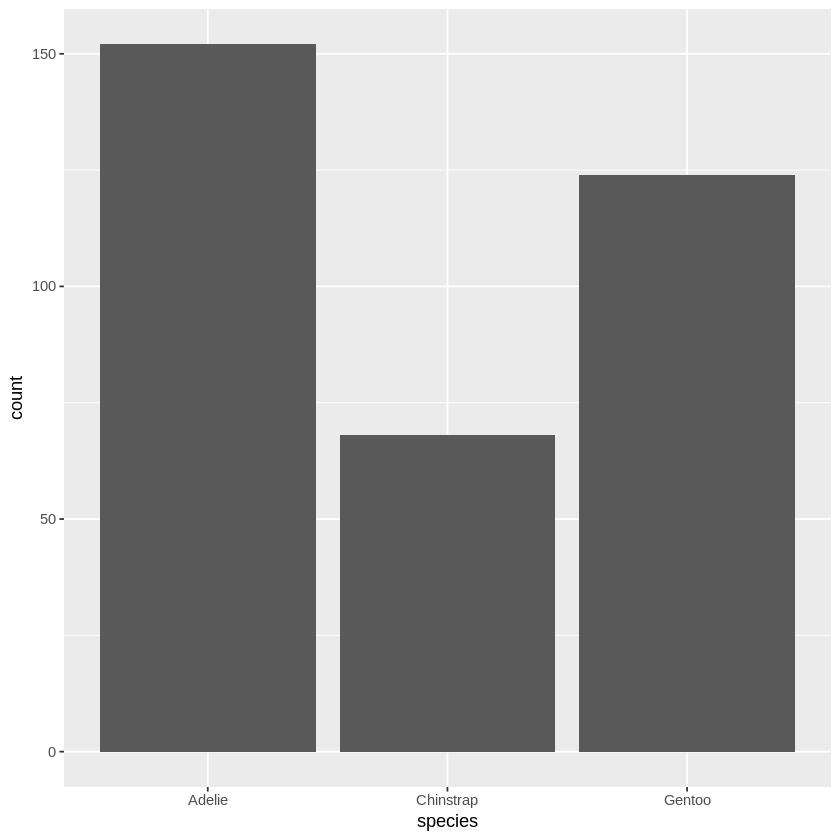

In [ ]:
ggplot(penguins, aes(x = species)) +
  geom_bar()

Je hoeft bij dit grafiektype alleen op te geven wat je op de x-as wilt, de 'count' (= het aantal) rekent R zelf standaard voor je uit op basis van de gegeven data.

Als je de x-as op volgorde van hoogste aantal wilt zetten, moet je (in dit geval) van 'species' een factor maken:

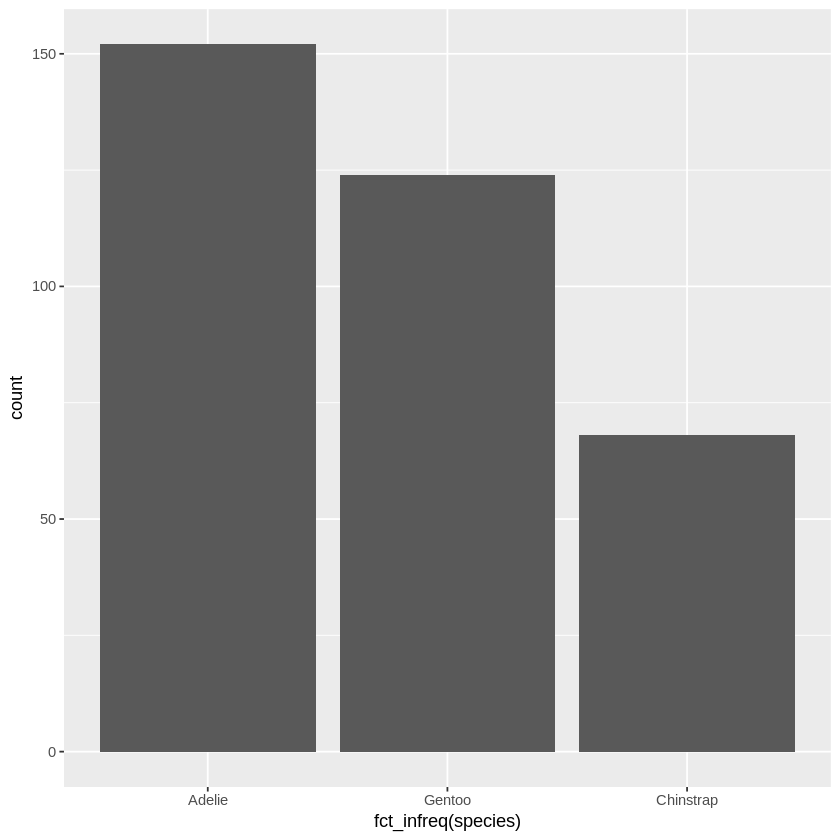

In [ ]:
ggplot(penguins, aes(x = fct_infreq(species))) +
  geom_bar()

We kunnen met kleur een tweede variabele (naast soort pinguin) toevoegen, namelijk op welk eiland de pinguins voorkomen:

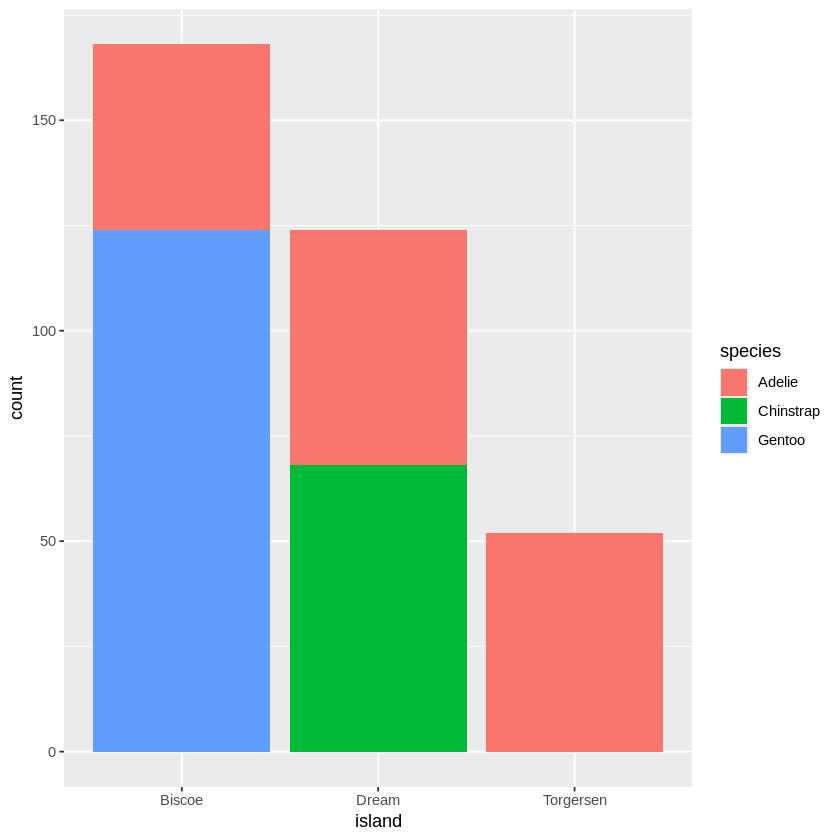

In [ ]:
ggplot(penguins, aes(x = island, fill = species)) +
  geom_bar()

Als we niet de absolute maar de relatieve verdeling van de pinguins over de eilanden willen zien, kan dat ook:

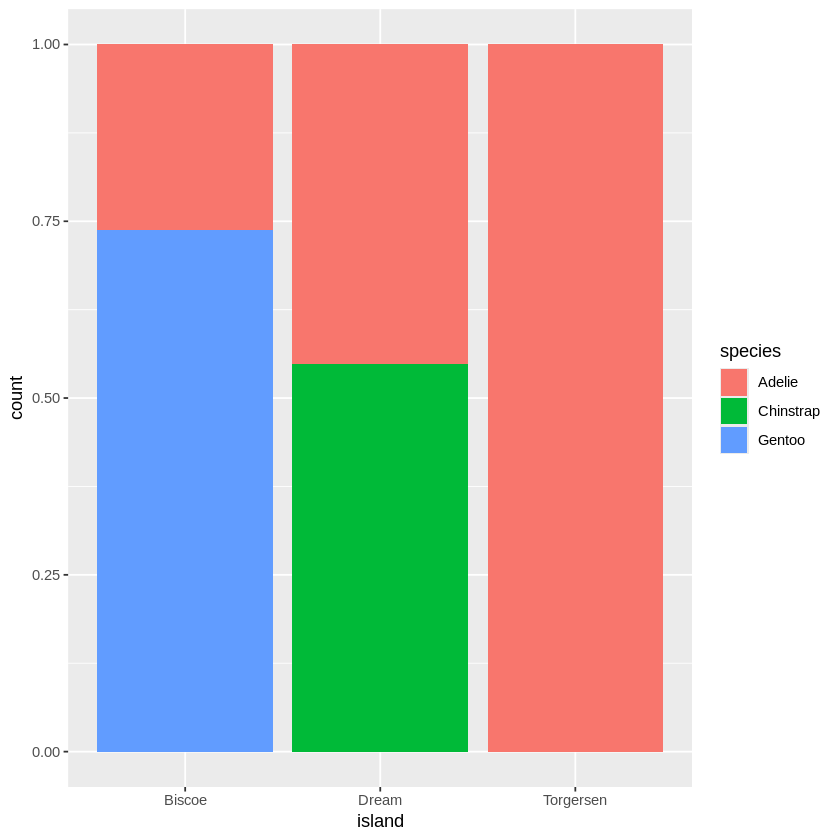

In [ ]:
ggplot(penguins, aes(x = island, fill = species)) +
  geom_bar(position = "fill")

## geom_histogram
Met een histogram kun je de frequentieverdeling van een bepaalde variabele laten zien.<br>
We beginnen met een basisversie, waarbij we de body_mass op de x-as zetten:



Warning message:
“Removed 2 rows containing non-finite outside the scale range (`stat_bin()`).”


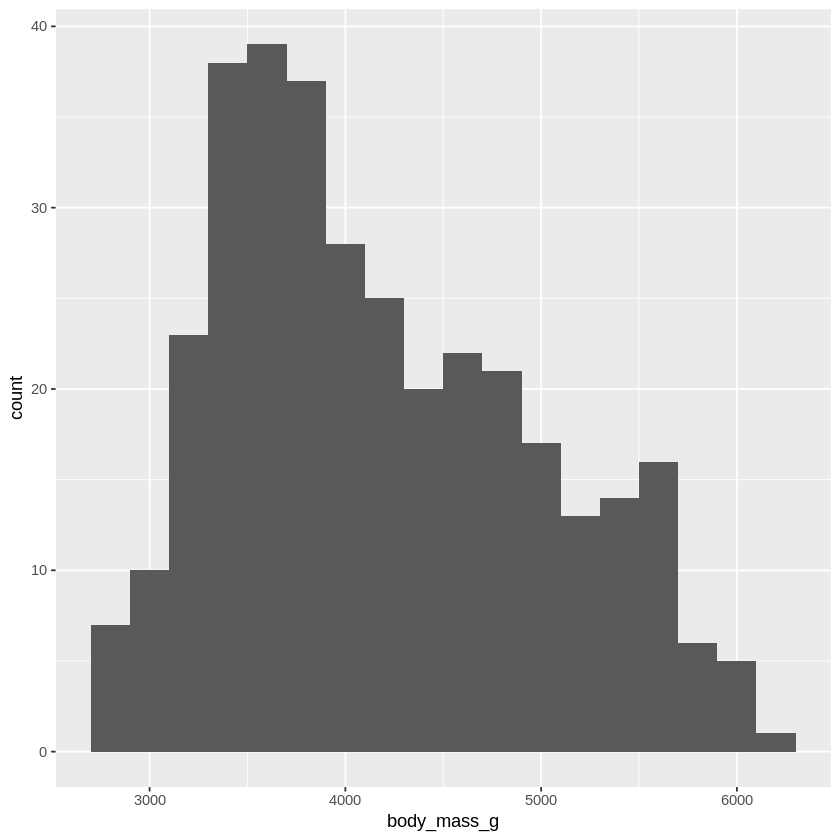

In [ ]:
ggplot(penguins, aes(x = body_mass_g)) +
  geom_histogram(binwidth = 200)

Met 'binwidth' kun je het aantal klassen op de x-as aangeven. We hebben nu 200 gekozen, maar misschien is bij deze x-as (de body_mass) 20 of 2.000 wel beter:

Warning message:
“Removed 2 rows containing non-finite outside the scale range (`stat_bin()`).”
Warning message:
“Removed 2 rows containing non-finite outside the scale range (`stat_bin()`).”


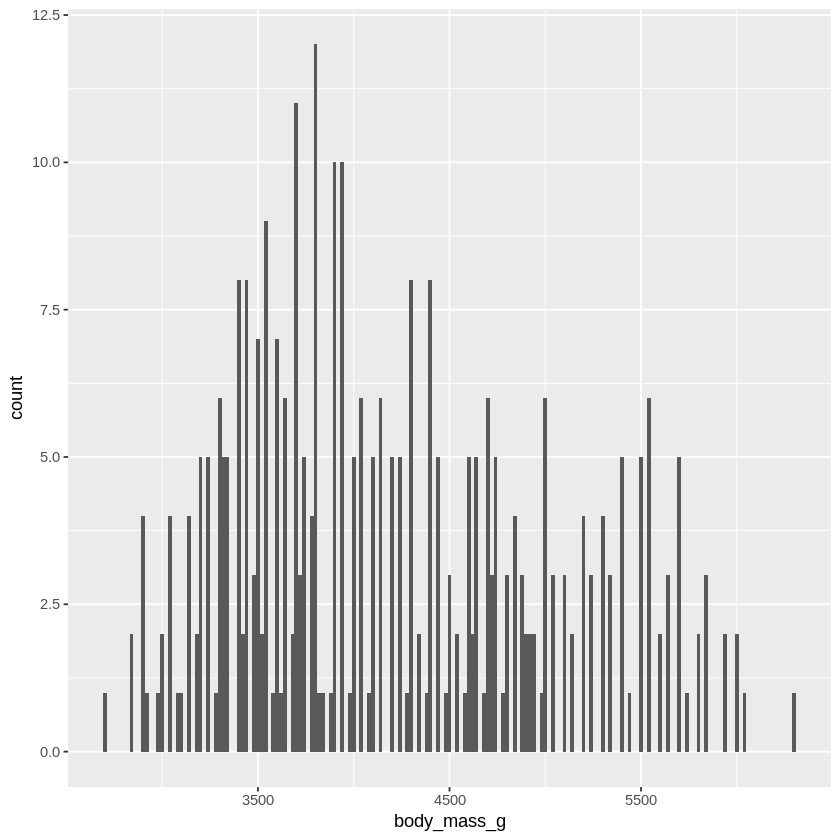

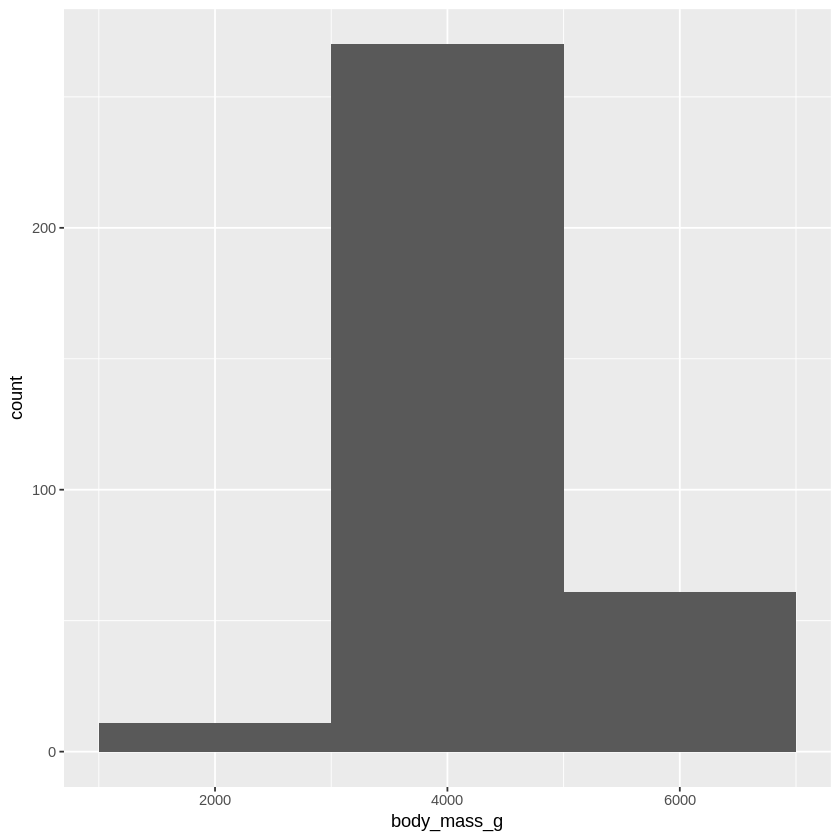

In [ ]:
ggplot(penguins, aes(x = body_mass_g)) +
  geom_histogram(binwidth = 20)
ggplot(penguins, aes(x = body_mass_g)) +
  geom_histogram(binwidth = 2000)

Het wordt er niet beter op, dus 200 is hier toch de betere 'bin'-grootte.

Voor meer informatie over histograms:<br>
https://ggplot2.tidyverse.org/reference/geom_histogram.html#ref-examples

### geom_density
Je kunt in plaats van staven ook een 'smooth' histogram maken = een histogram waarin alle punten met een vloeiende lijn zijn verbonden. Hiervoor gebruiken we de density-functie:

Warning message:
“Removed 2 rows containing non-finite outside the scale range
(`stat_density()`).”


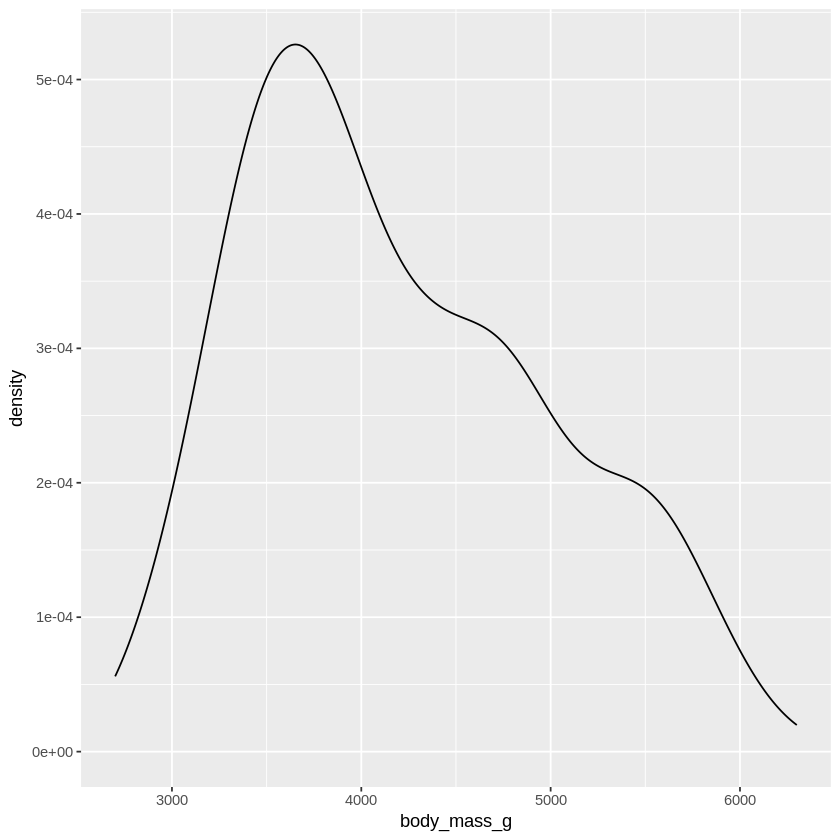

In [ ]:
ggplot(penguins, aes(x = body_mass_g)) +
  geom_density()

Zelfde soort grafiek, maar nu de verdeling van de body_mass per soort pinguin:

Warning message:
“Removed 2 rows containing non-finite outside the scale range
(`stat_density()`).”


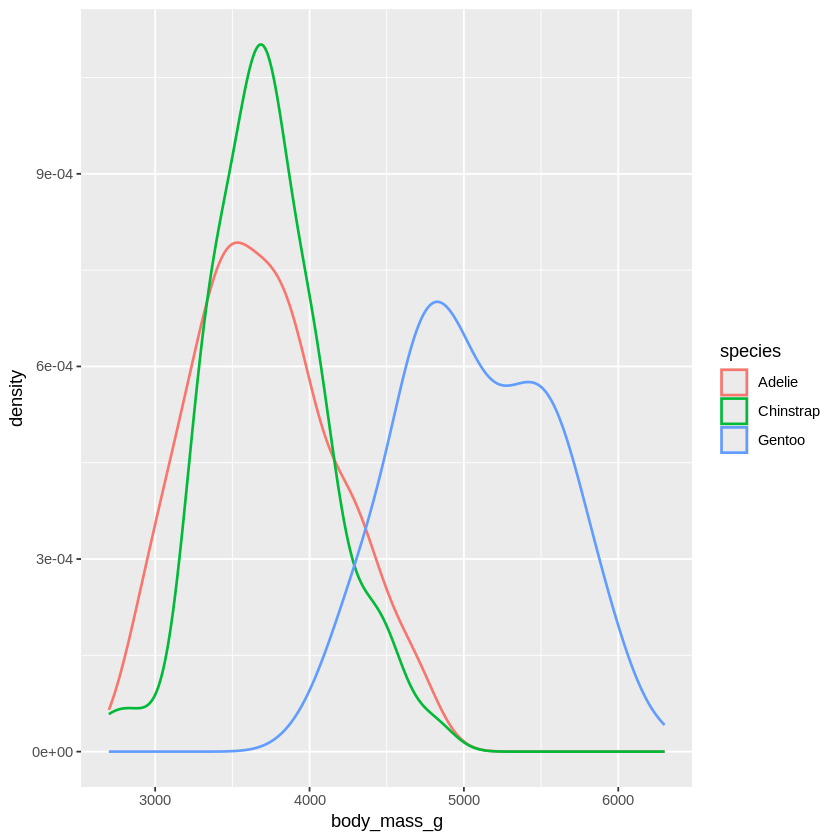

In [ ]:
ggplot(penguins, aes(x = body_mass_g, color = species)) +
  geom_density(linewidth = 0.75)

En een nog fraaiere versie van bovenstaande grafiek:

Warning message:
“Removed 2 rows containing non-finite outside the scale range
(`stat_density()`).”


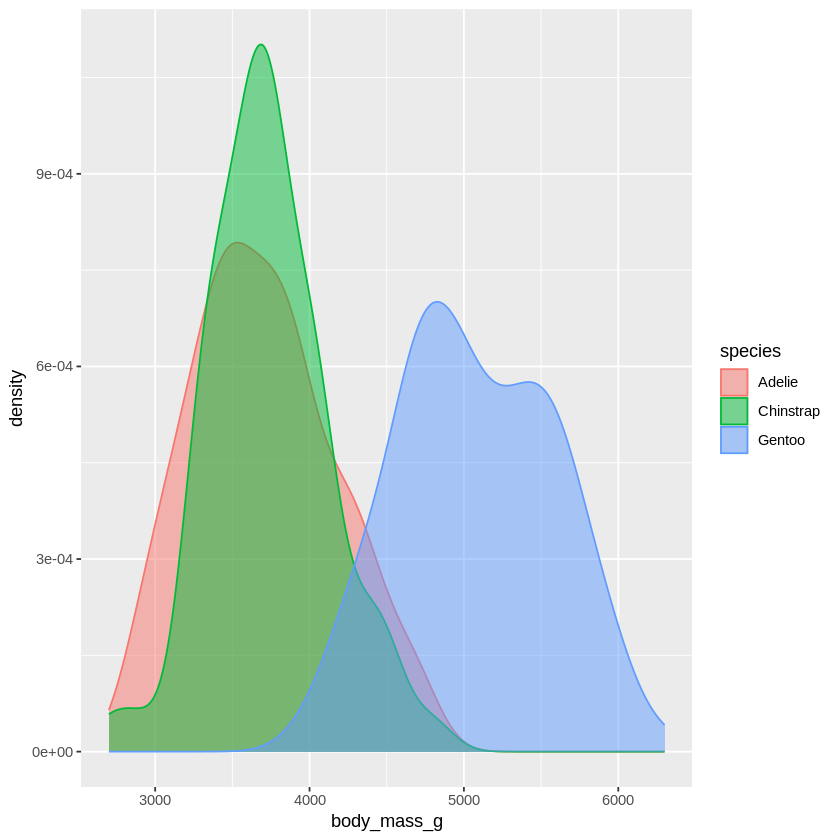

In [ ]:
ggplot(penguins, aes(x = body_mass_g, color = species, fill = species)) +
  geom_density(alpha = 0.5)

## geom_boxplot
Met een boxplot kun je in 1 grafiek een overzicht maken van minimum, 1e kwartiel, mediaan, 3e kwartiel en maximum van een bepaalde variabele. Hieronder is als voorbeeld de body_mass per soort pinguin genomen:

Warning message:
“Removed 2 rows containing non-finite outside the scale range
(`stat_boxplot()`).”


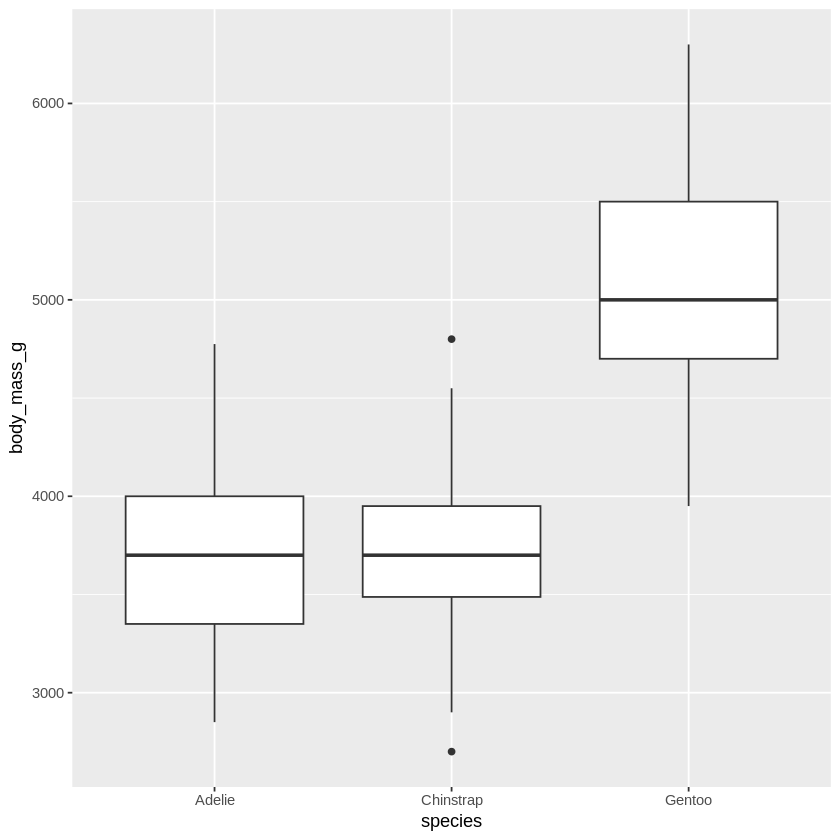

In [ ]:
ggplot(penguins, aes(x = species, y = body_mass_g)) +
  geom_boxplot()

Je kunt de boxplot ook 'flippen', waarbij de x- en y-as omgedraaid worden:

Warning message:
“Removed 2 rows containing non-finite outside the scale range
(`stat_boxplot()`).”


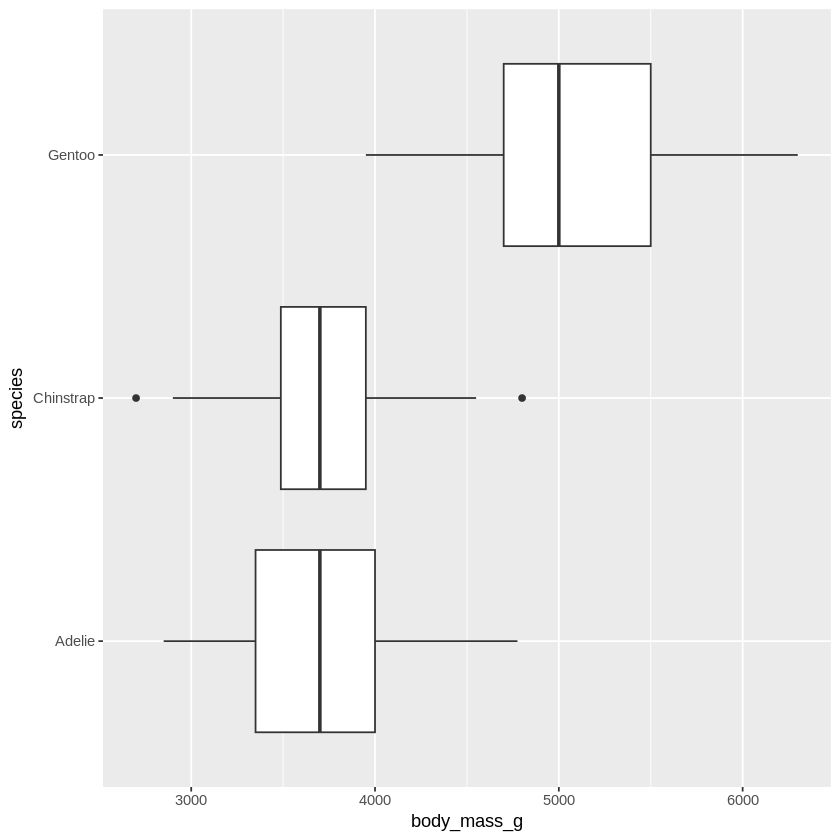

In [ ]:
ggplot(penguins, aes(x = species, y = body_mass_g)) +
  geom_boxplot() +
  coord_flip()

# Grafieken opslaan
Als je al die mooie grafieken wilt bewaren als plaatje voor later gebruik in een verslag, dan kan dat:

Warning message:
“Removed 2 rows containing missing values or values outside the scale range
(`geom_point()`).”
Saving 7 x 7 in image
Warning message:
“Removed 2 rows containing missing values or values outside the scale range
(`geom_point()`).”


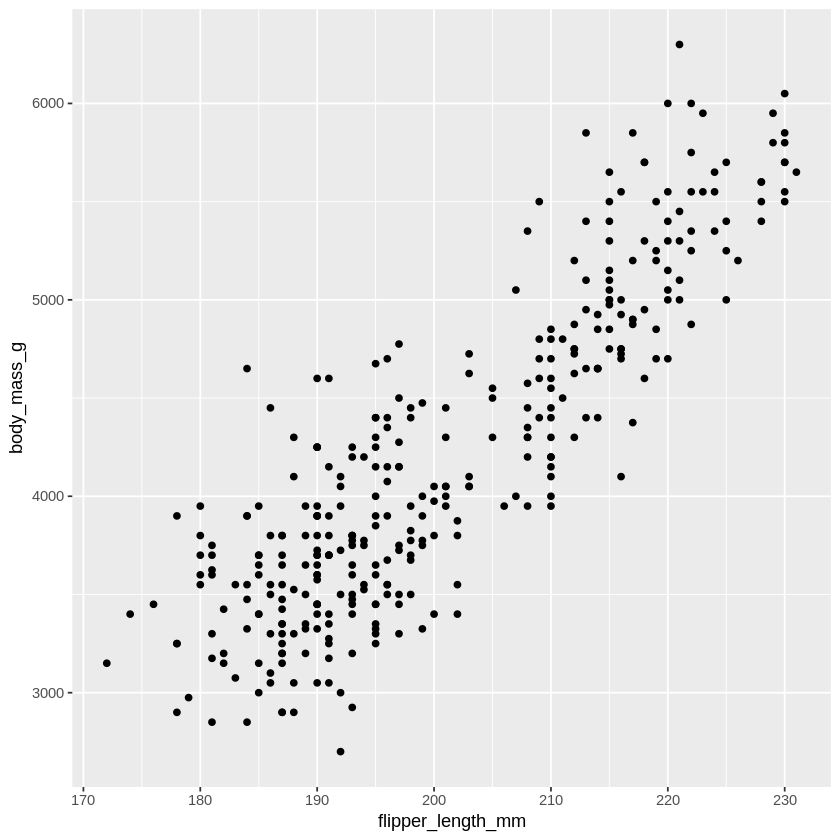

In [ ]:
ggplot(penguins, aes(x = flipper_length_mm, y = body_mass_g)) +
  geom_point()
ggsave(filename = "penguin-plot.png")

Je kunt het .png bestand terugvinden in de 'content'-folder en van daaruit downloaden op je eigen pc.

# De Grammatica van de Grafiek
Onderstaand template geeft een algemeen voorschrift voor hoe je grafieken in R met ggplot kunt maken:<br>

ggplot(data = [DATA]) + <br>
  [GEOM_FUNCTION](<br>
     mapping = aes([MAPPINGS]),<br>
     stat = [STAT],<br>
     position = [POSITION]<br>
  ) +<br>
  [COORDINATE_FUNCTION] +<br>
  [FACET_FUNCTION]<br>

Met dit template kun je nu (in theorie ;) alle mogelijke grafieken in R maken - Succes!


# Huiswerk
Maak de volgende opgaven uit het boek:<br>
- 1.4.3 (staafdiagram en histogram)<br>
- 1.5.5 (alle grafiektypen)<br>
- 1.6.1 (opslaan grafieken)


## 1.4.3.1

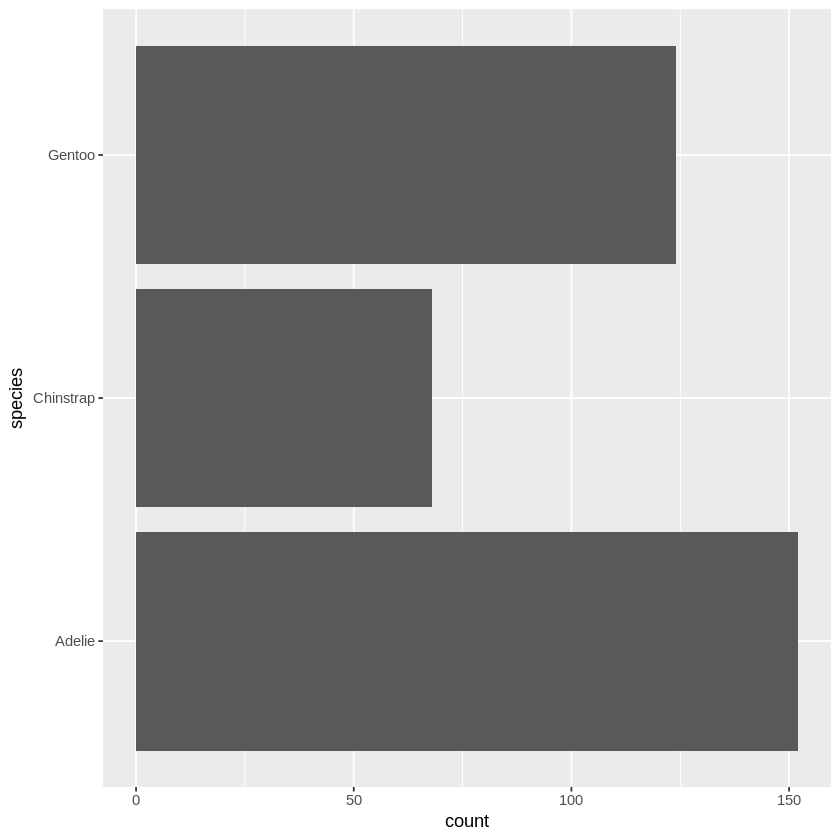

In [ ]:
ggplot(penguins, aes(y=species)) +
  geom_bar()

## 1.4.3.2

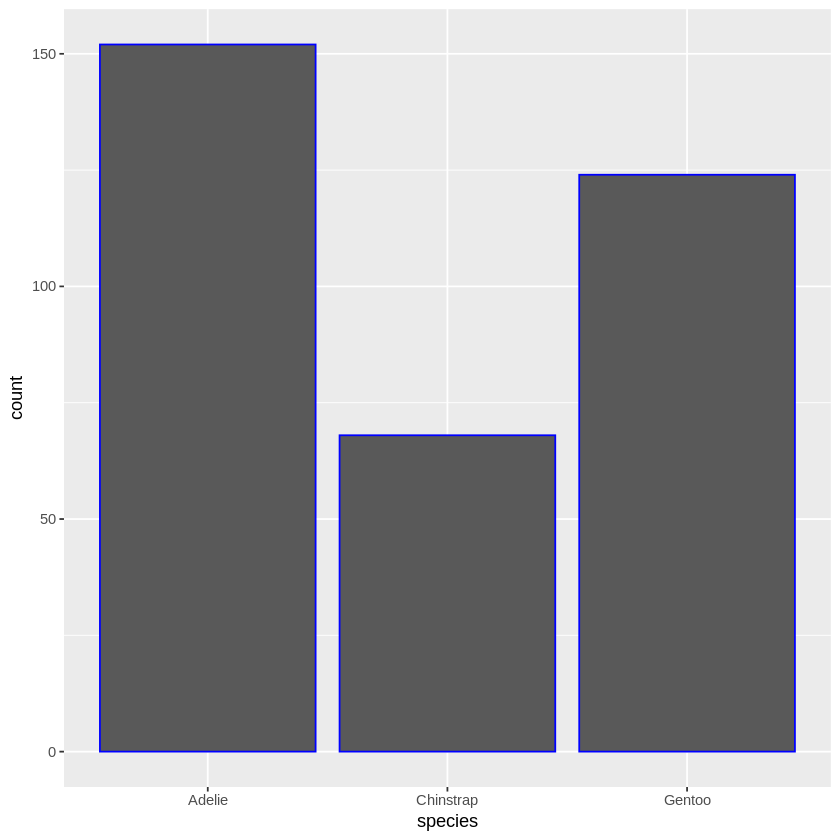

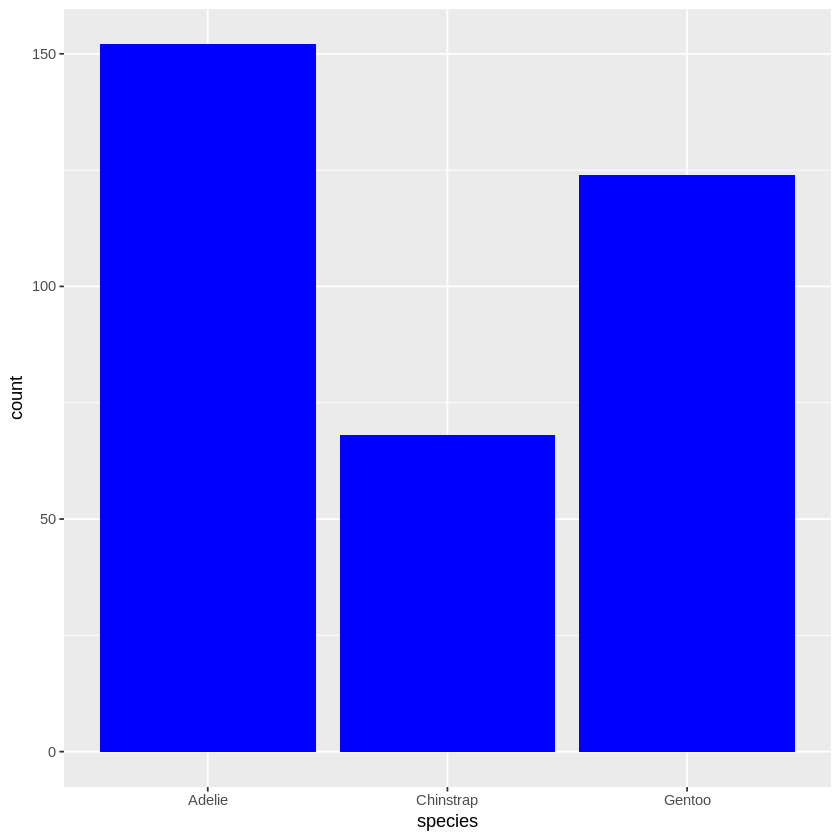

In [ ]:
ggplot(penguins, aes(x = species)) +
  geom_bar(color = "blue")

ggplot(penguins, aes(x = species)) +
  geom_bar(fill = "blue")

## 1.4.3.3
Met bins kun je het aantal klassen aangeven.

## 1.4.3.4

In [ ]:
diamonds

carat,cut,color,clarity,depth,table,price,x,y,z
<dbl>,<ord>,<ord>,<ord>,<dbl>,<dbl>,<int>,<dbl>,<dbl>,<dbl>
0.23,Ideal,E,SI2,61.5,55,326,3.95,3.98,2.43
0.21,Premium,E,SI1,59.8,61,326,3.89,3.84,2.31
0.23,Good,E,VS1,56.9,65,327,4.05,4.07,2.31
0.29,Premium,I,VS2,62.4,58,334,4.20,4.23,2.63
0.31,Good,J,SI2,63.3,58,335,4.34,4.35,2.75
0.24,Very Good,J,VVS2,62.8,57,336,3.94,3.96,2.48
0.24,Very Good,I,VVS1,62.3,57,336,3.95,3.98,2.47
0.26,Very Good,H,SI1,61.9,55,337,4.07,4.11,2.53
0.22,Fair,E,VS2,65.1,61,337,3.87,3.78,2.49


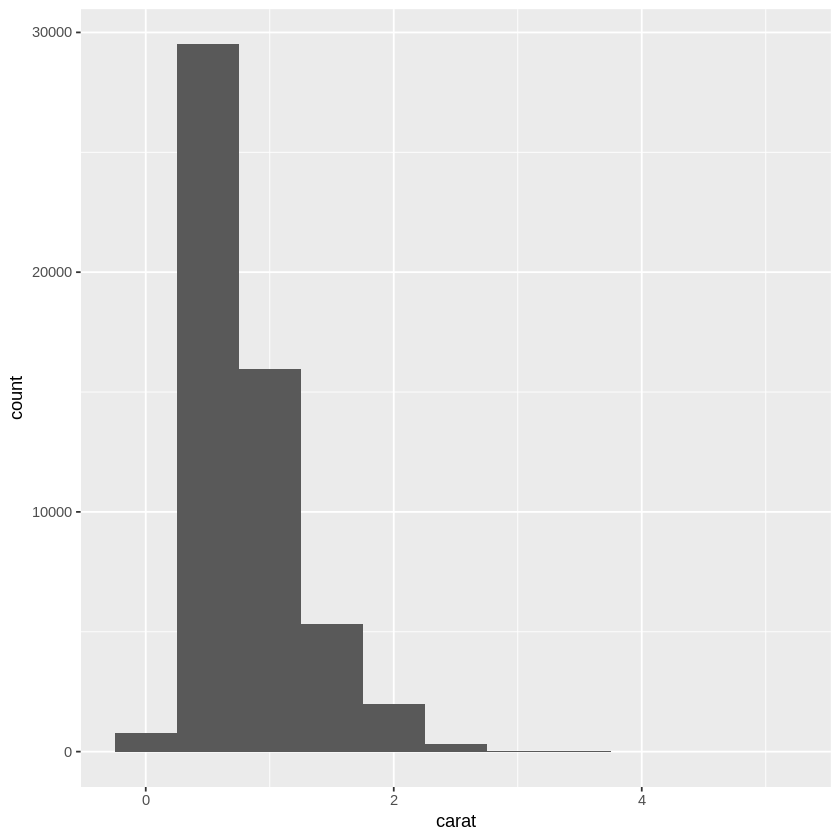

In [ ]:
ggplot(diamonds, aes(x=carat)) +
  geom_histogram(binwidth = 0.5)

## 1.5.5.1

In [ ]:
mpg

manufacturer,model,displ,year,cyl,trans,drv,cty,hwy,fl,class
<chr>,<chr>,<dbl>,<int>,<int>,<chr>,<chr>,<int>,<int>,<chr>,<chr>
audi,a4,1.8,1999,4,auto(l5),f,18,29,p,compact
audi,a4,1.8,1999,4,manual(m5),f,21,29,p,compact
audi,a4,2.0,2008,4,manual(m6),f,20,31,p,compact
audi,a4,2.0,2008,4,auto(av),f,21,30,p,compact
audi,a4,2.8,1999,6,auto(l5),f,16,26,p,compact
audi,a4,2.8,1999,6,manual(m5),f,18,26,p,compact
audi,a4,3.1,2008,6,auto(av),f,18,27,p,compact
audi,a4 quattro,1.8,1999,4,manual(m5),4,18,26,p,compact
audi,a4 quattro,1.8,1999,4,auto(l5),4,16,25,p,compact


## 1.5.5.2

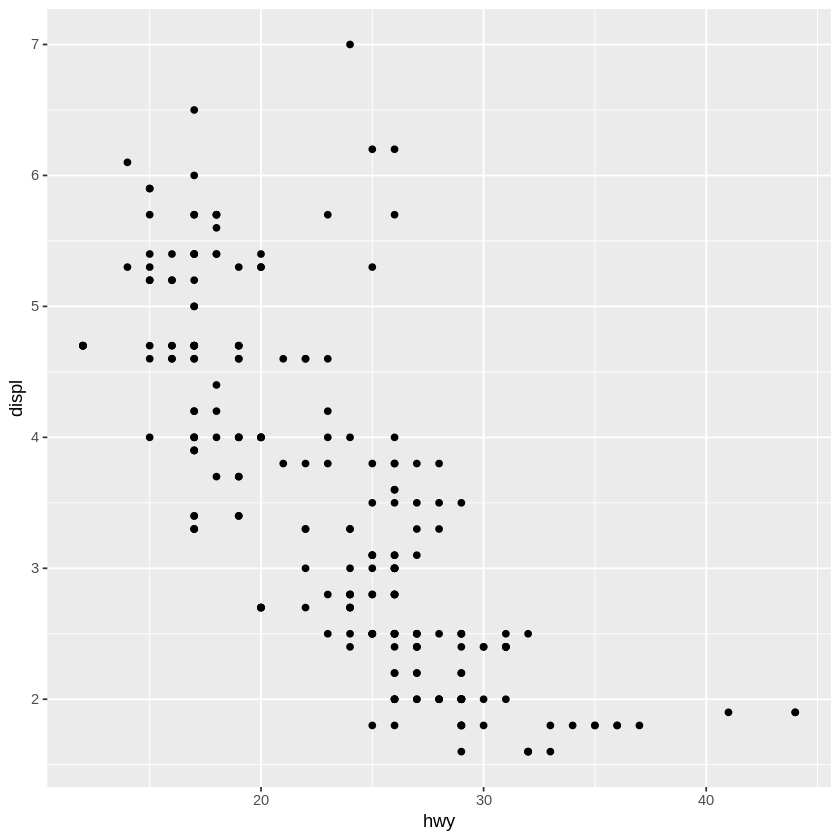

In [ ]:
ggplot(mpg, aes(x = hwy, y = displ)) +
  geom_point()

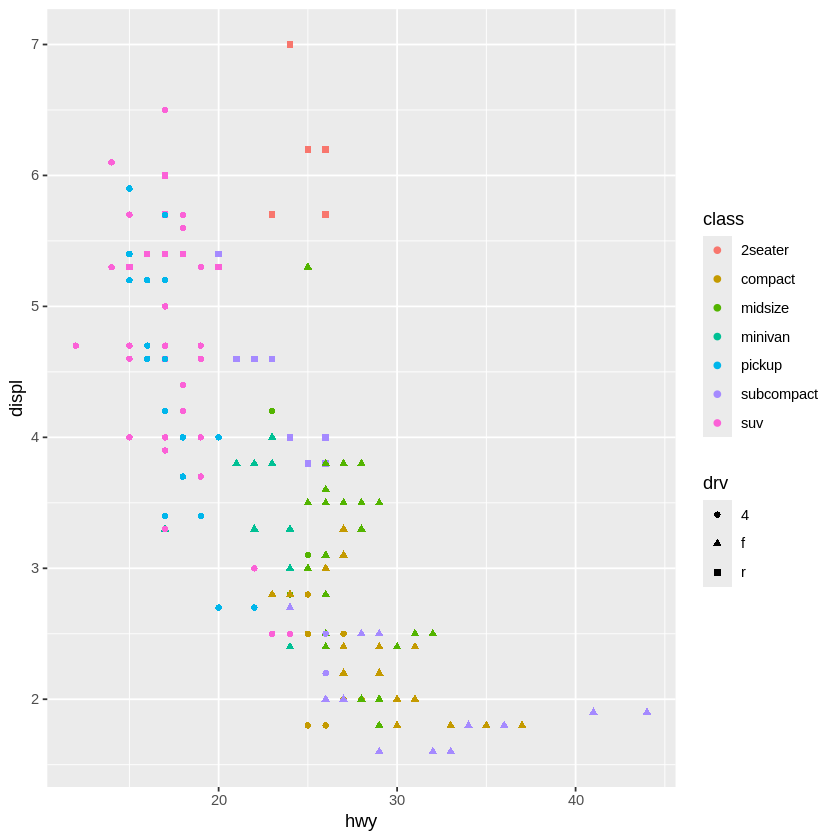

In [ ]:
ggplot(mpg, aes(x = hwy, y = displ)) +
  geom_point(aes(colour=class, shape=drv))

Nog te maken: 1.5.5.3 - 1.5.5.7 en 1.6.1.1 - 1.6.1.2

# 9.5 Statistical transformations

## 9.5.1
De standaard geom voor stat_summary() is 'pointrange'. Dit betekent dat als je niet expliciet een geom geeft, er een punt wordt weergegeven bij de samenvattende statistiek (fun) met verticale lijnen die lopen van fun.min tot fun.max.

Aangezien de standaard geom 'pointrange' is, kun je 'stat_summary' vervangen door de geom 'pointrange':

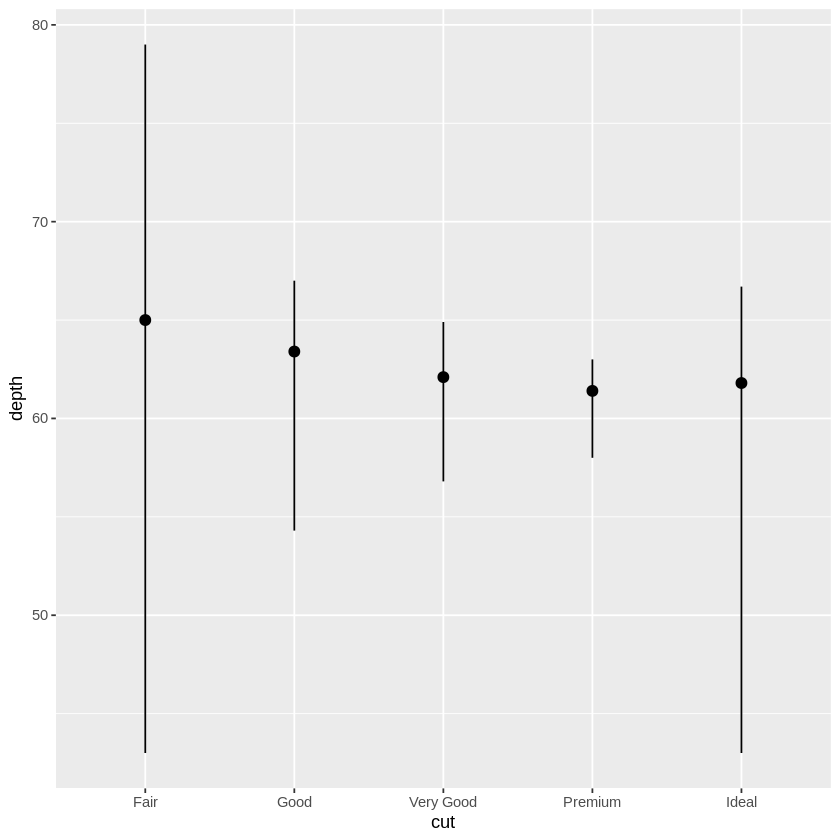

In [3]:
ggplot(data = diamonds, aes(x = cut, y = depth)) +
  geom_pointrange(
    stat = "summary",
    fun = median,
    fun.min = min,
    fun.max = max
  )

## 9.5.2
Both geom_col() and geom_bar() are used to create bar charts in ggplot2, but they handle the y-axis mapping differently:

geom_bar(): This is primarily used for displaying the count of observations within each category. By default, geom_bar() calculates the number of cases at each x position and uses that as the height of the bar. You only need to provide the x aesthetic (a categorical variable), and it automatically performs a statistical transformation (stat = "count").

geom_col(): This is a simpler version of geom_bar() where you directly map a pre-computed value to the height of the bars. It requires both x and y aesthetics. The y aesthetic represents the value you want to plot, and geom_col() assumes these values are already calculated (it uses stat = "identity").

In short: Use geom_bar() when you want to count observations, and geom_col() when you already have the values you want to plot as bar heights.

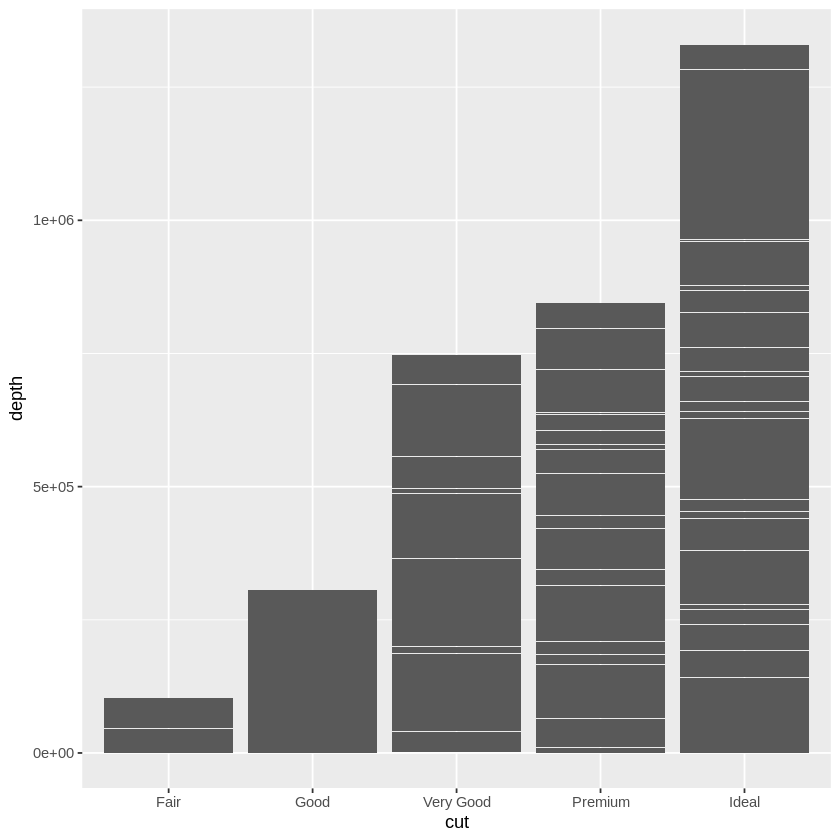

In [4]:
ggplot(data = diamonds, aes(x = cut, y = depth)) +
  geom_col()

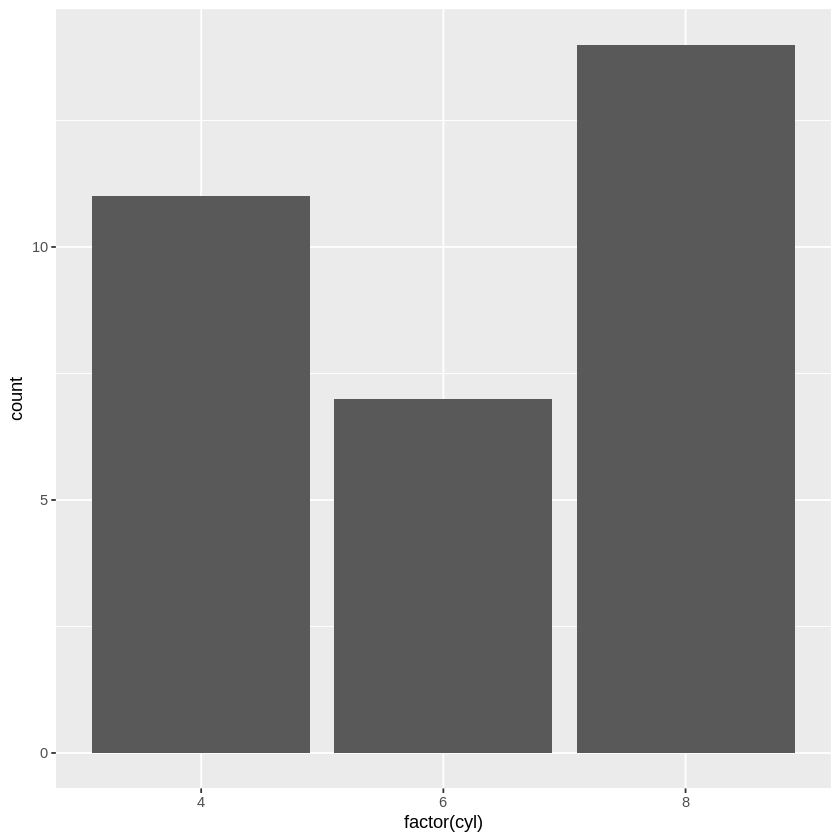

In [5]:
ggplot(mtcars, aes(x = factor(cyl))) +
  geom_bar()

## 9.5.3
From the notebook content, here are some geom and stat pairs that are discussed or demonstrated:
<ul>
<li>geom_point() (often implicitly with stat_identity if direct values are mapped, but can also be used with other stats like stat_summary)</li>
<li>geom_bar() is paired with stat_count (default for geom_bar())</li>
<li>geom_col() is paired with stat_identity (default for geom_col())</li>
<li>geom_histogram() is paired with stat_bin (default for geom_histogram())</li>
<li>geom_density() is paired with stat_density (default for geom_density())</li>
<li>geom_boxplot() is paired with stat_boxplot (default for geom_boxplot())</li>
<li>geom_pointrange() is explicitly used with stat_summary in the example.</li>
</ul>

## 9.5.4
The stat_smooth() function (often used via geom_smooth()) in ggplot2 computes several variables, which are then typically mapped to aesthetics:

Variables computed:
<ul>
<li>x: The x-coordinates along the smoothed line.</li>
<li>y: The y-coordinates along the smoothed line (the fitted values).</li>
<li>ymin: The lower bound of the confidence interval around the smoothed line.</li>
<li>ymax: The upper bound of the confidence interval around the smoothed line.</li>
<li>se: The standard error of the fitted values.</li>
</ul>

Arguments that control its behavior:
<ul>
<li>method: This is a crucial argument that specifies the smoothing method to use. Common methods include:<br>
"loess": Locally estimated scatterplot smoothing (default for smaller datasets).<br>
"gam": Generalized additive models (default for larger datasets).<br>
"lm": Linear model.<br>
"glm": Generalized linear models.<br>
"rlm": Robust linear models (from the MASS package).</li>
<li>formula: The formula to use for the smoothing method, e.g., y ~ x (default), y ~ poly(x, 2) for a polynomial fit, or y ~ log(x).</li>
<li>se: A logical value (TRUE or FALSE) indicating whether to display standard error bands around the smooth (default is TRUE).</li>
<li>level: The level of confidence interval to use for the standard error bands (e.g., 0.95 for a 95% confidence interval).</li>
<li>fullrange: A logical value (TRUE or FALSE) indicating whether the smoothing should span the full range of the plot or just the range of the data (default is FALSE).</li>
<li>span: For method = "loess", this controls the degree of smoothing. Smaller values produce wigglier lines, larger values produce smoother lines (values between 0 and 1).</li>
<li>na.rm: A logical value indicating whether NA values should be removed (default is FALSE).</li>
</ul>

## 9.5.5
Voor de eerste grafiek is er slechts één x-variabele (cut), dus de verhoudingen worden standaard correct berekend.

Voor de tweede grafiek is het probleem: ggplot2 berekent standaard de verhoudingen afzonderlijk voor elke vulgroep. Dat betekent dat after_stat(prop) nu in verhouding is binnen elke kleur, niet in verhouding binnen de hele x-categorie.

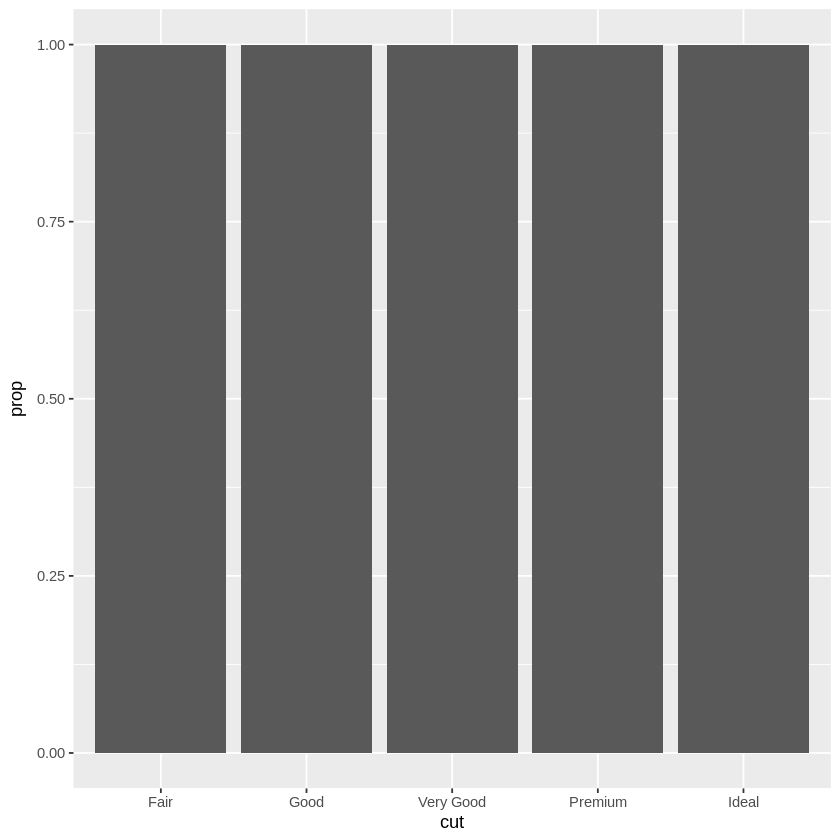

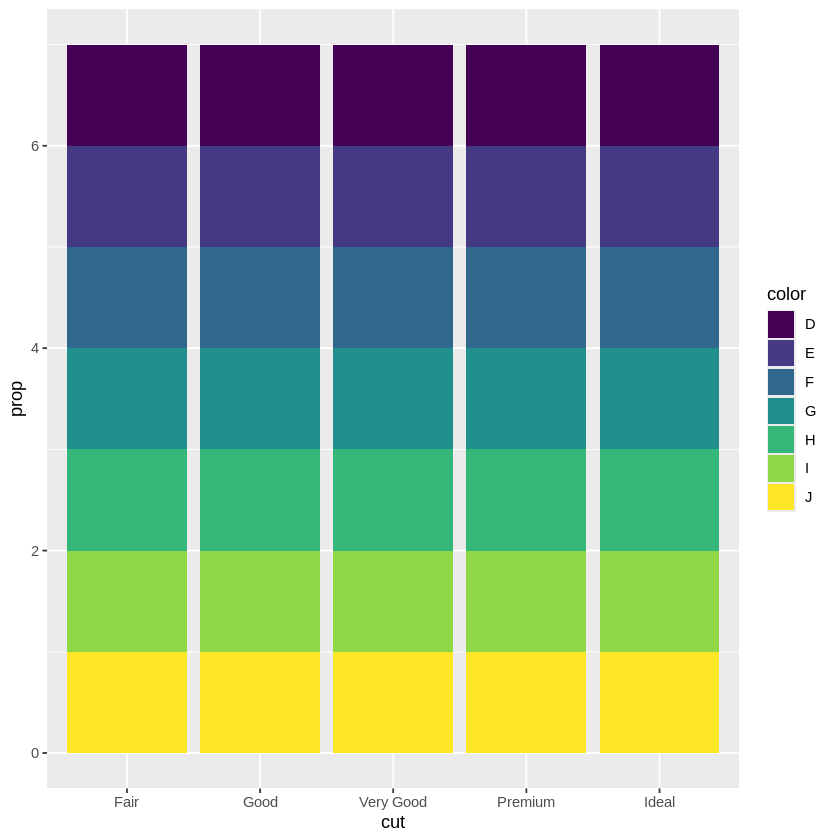

In [6]:
ggplot(diamonds, aes(x = cut, y = after_stat(prop))) +
  geom_bar()
ggplot(diamonds, aes(x = cut, fill = color, y = after_stat(prop))) +
  geom_bar()

# 9.6 Position adjustments

## 9.6.1
Problemen met de grafiek:
<ul>
<li>Overplotting: Both cty (city miles per gallon) and hwy (highway miles per gallon) are integers, meaning multiple cars can have the exact same values. This causes points to overlap heavily, making it difficult to discern the density of observations.</li>
<li>Lack of context: The plot doesn't differentiate between car classes or manufacturers, which could reveal interesting patterns or groupings within the data.</li>
<li>No regression line or trend: While not strictly necessary for every plot, a trend line (e.g., linear or smooth) could help summarize the relationship between cty and hwy.</li>
<li>No labeling or titles: Axis labels and a title are missing, which makes interpretation more difficult for someone unfamiliar with the dataset.</li>

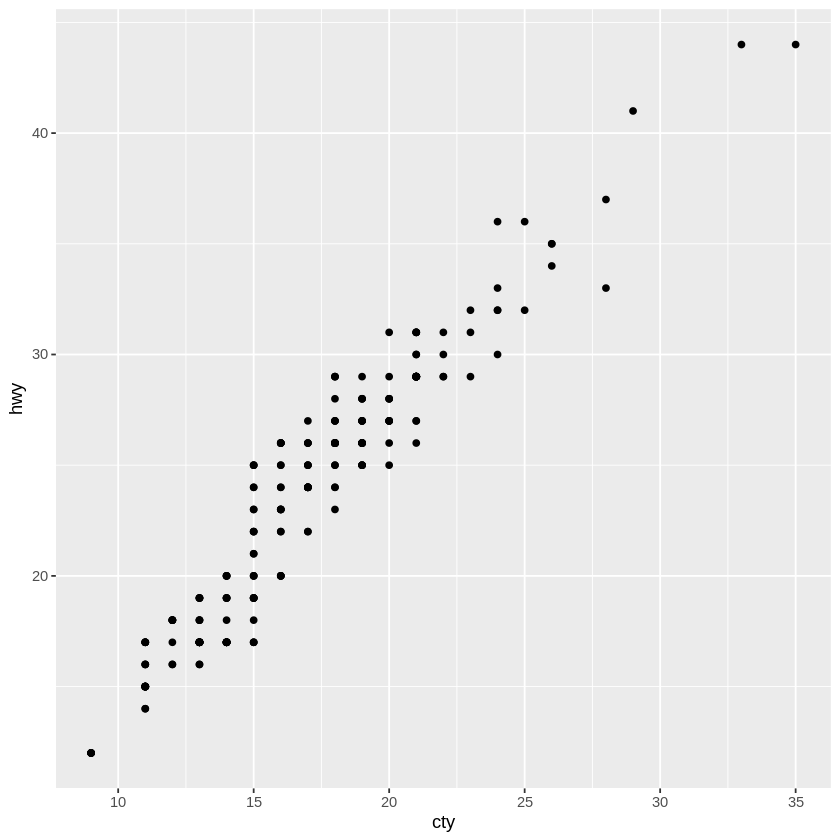

In [7]:
ggplot(mpg, aes(x = cty, y = hwy)) +
  geom_point()

### Improved plot for `cty` vs `hwy`

`geom_smooth()` using formula = 'y ~ x'


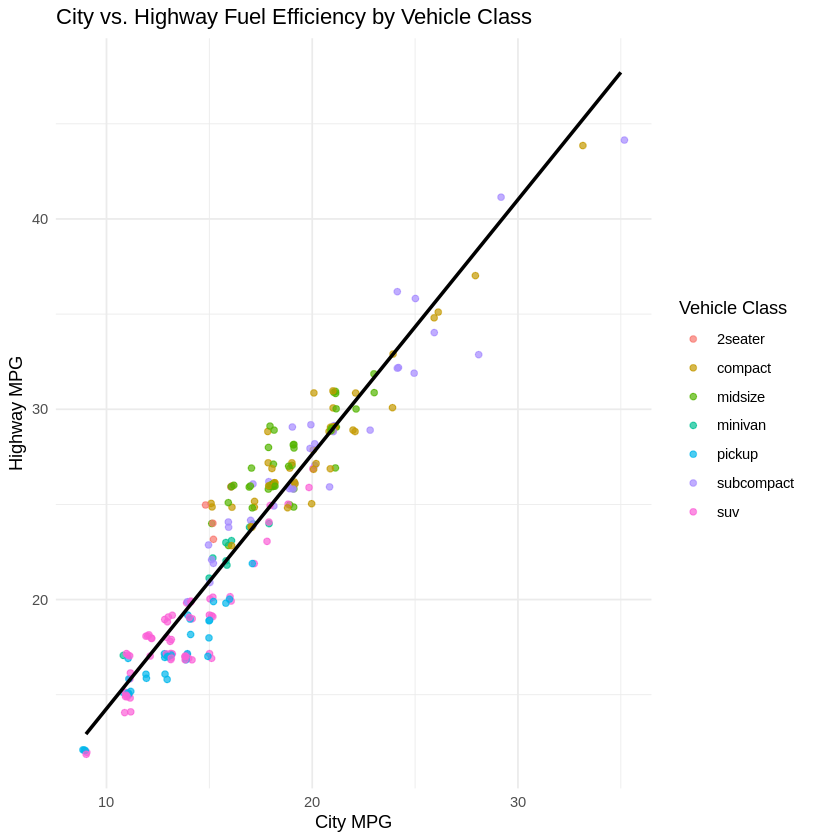

In [8]:
ggplot(mpg, aes(x = cty, y = hwy, color = class)) +
  geom_jitter(width = 0.2, height = 0.2, alpha = 0.7) + # Use jitter to reduce overplotting
  geom_smooth(method = 'lm', se = FALSE, color = 'black') + # Add a linear trend line without confidence interval
  labs(
    title = "City vs. Highway Fuel Efficiency by Vehicle Class",
    x = "City MPG",
    y = "Highway MPG",
    color = "Vehicle Class"
  ) +
  theme_minimal() # Apply a minimalist theme

## 9.6.2
There is no functional or visual difference between these two plots.
<p>
Why?
<p>
When you use geom_point(), the default position adjustment is position = "identity". This means that ggplot2 plots each point exactly at its specified x and y coordinates without any modification to avoid overlap. The points are rendered precisely where the data values dictate.

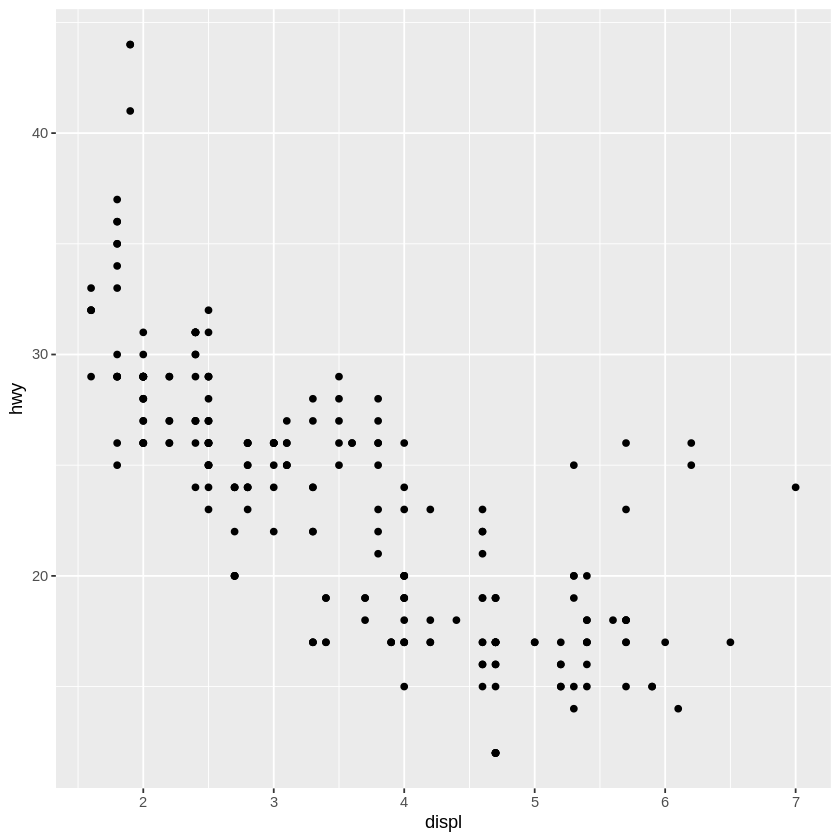

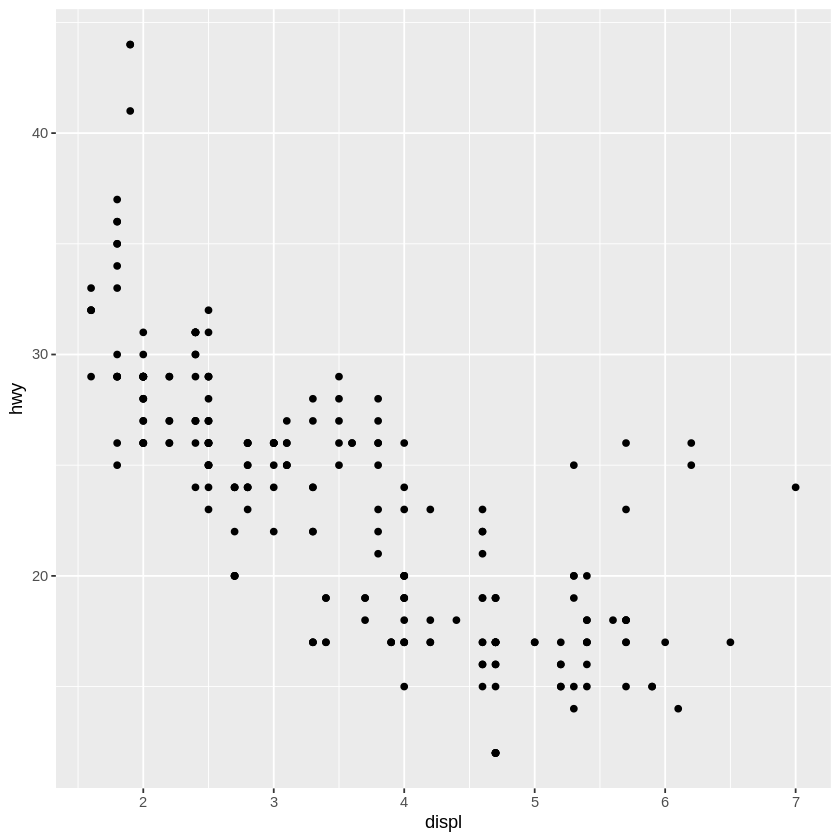

In [9]:
ggplot(mpg, aes(x = displ, y = hwy)) +
  geom_point()
ggplot(mpg, aes(x = displ, y = hwy)) +
  geom_point(position = "identity")

## 9.6.3
width → horizontale jitter

height → verticale jitter

Pas ze aan om overplotten te verminderen zonder punten te ver van hun werkelijke coördinaten te spreiden.

## 9.6.4
geom_jitter() = spreidt punten om overlap te verminderen, behoudt individualiteit.

geom_count() = schaalt de puntgrootte om aan te geven hoeveel punten elke exacte positie innemen.

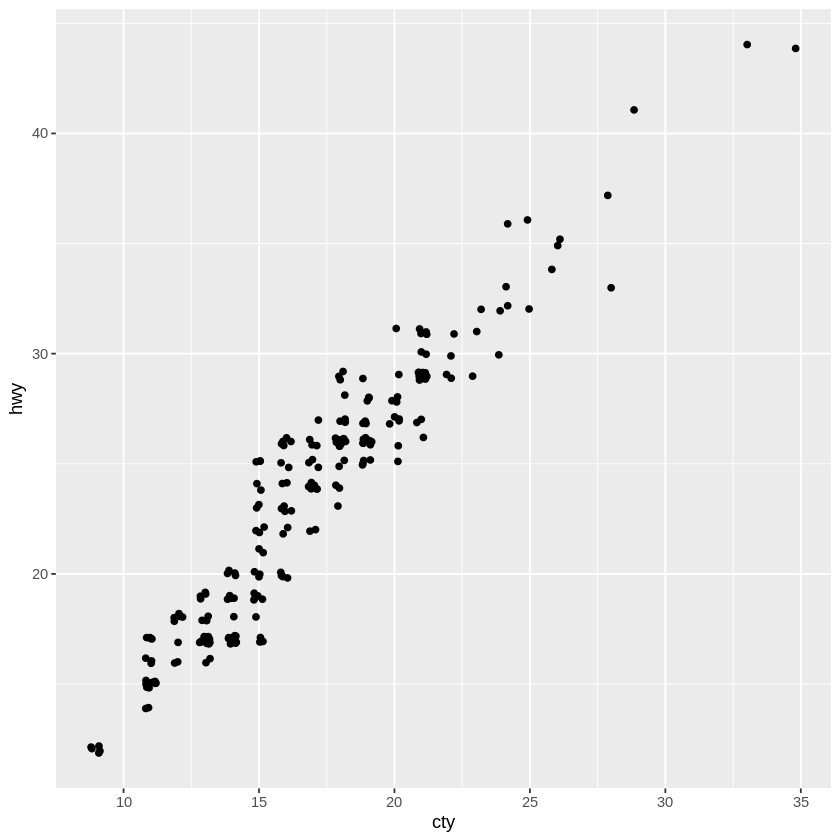

In [10]:
ggplot(mpg, aes(x = cty, y = hwy)) +
  geom_jitter(width = 0.2, height = 0.2)

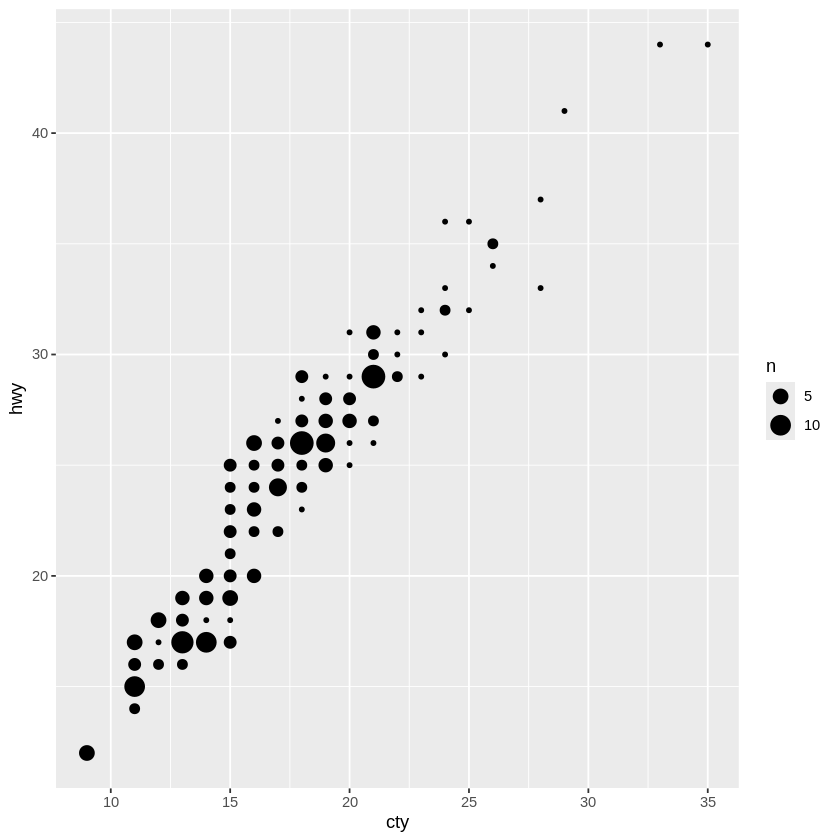

In [11]:
ggplot(mpg, aes(x = cty, y = hwy)) +
  geom_count()

## 9.6.5
The default position adjustment for geom_boxplot() is position = "dodge". This means that when you map a variable to fill or color within geom_boxplot(), the box plots for different groups will be automatically placed side-by-side to prevent overlap.
<p>
Here's a visualization using the mpg dataset that demonstrates this, showing the highway fuel efficiency (hwy) for different car classes, separated by drive train (drv). You'll observe that the box plots for 'f', 'r', and '4' drive types are dodged for each car class.

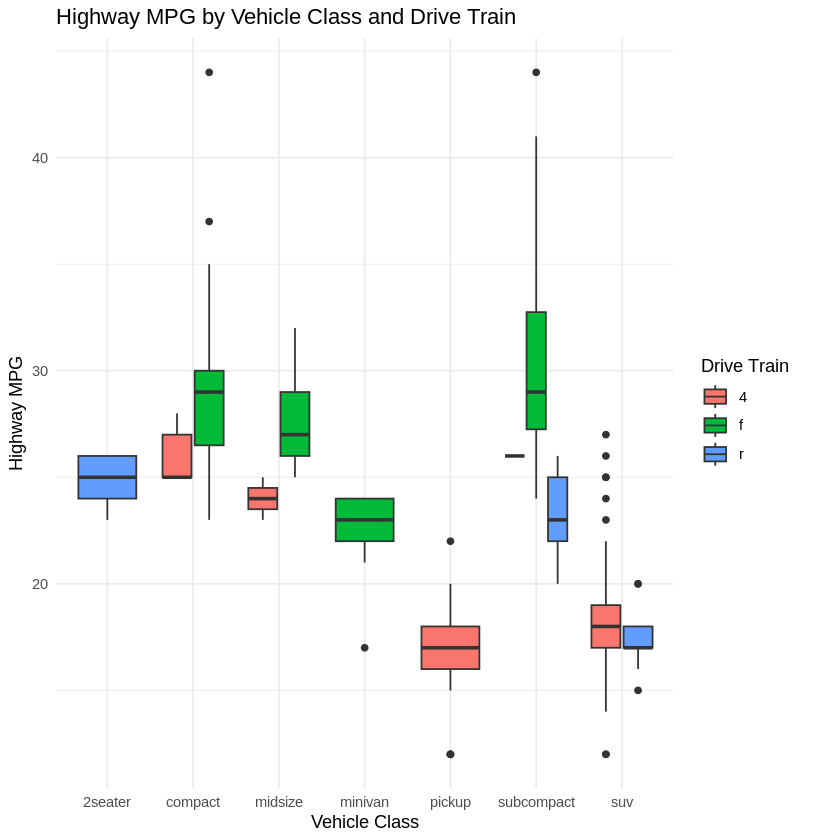

In [12]:
ggplot(mpg, aes(x = class, y = hwy, fill = drv)) +
  geom_boxplot() +
  labs(
    title = "Highway MPG by Vehicle Class and Drive Train",
    x = "Vehicle Class",
    y = "Highway MPG",
    fill = "Drive Train"
  ) +
  theme_minimal()

# 9.7 Coordinate systems

## 9.7.1
Turn a stacked bar chart into a pie chart using coord_polar().

In [13]:
bar <- ggplot(data = diamonds) +
  geom_bar(
    mapping = aes(x = "", fill = clarity),  # x is empty to stack everything in one bar
    width = 1
  ) +
  theme_void()  # removes axes, gridlines, etc.

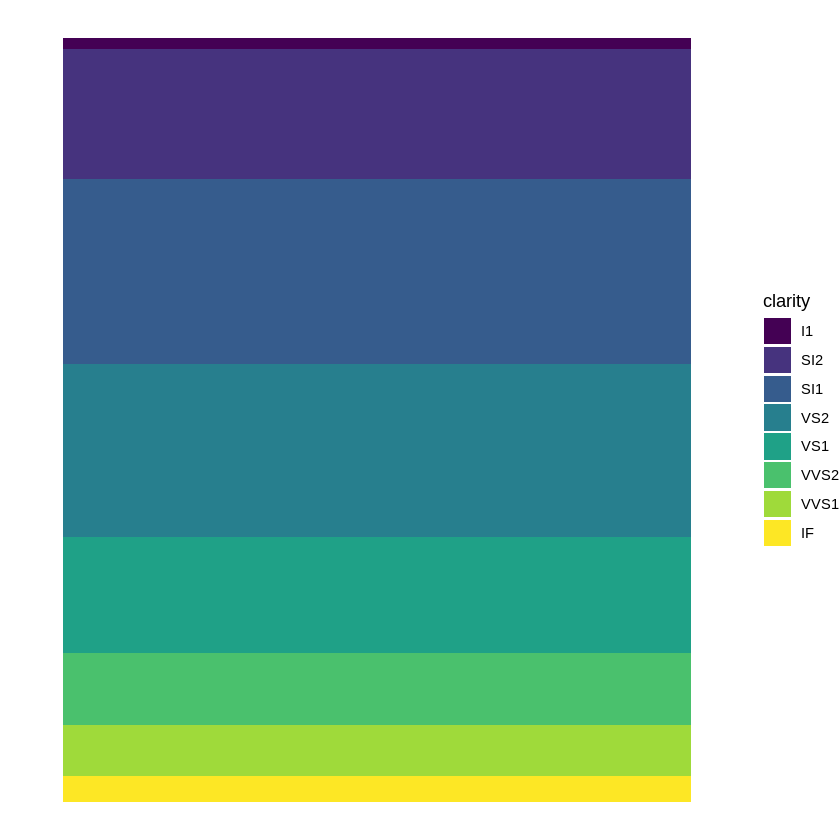

In [14]:
bar

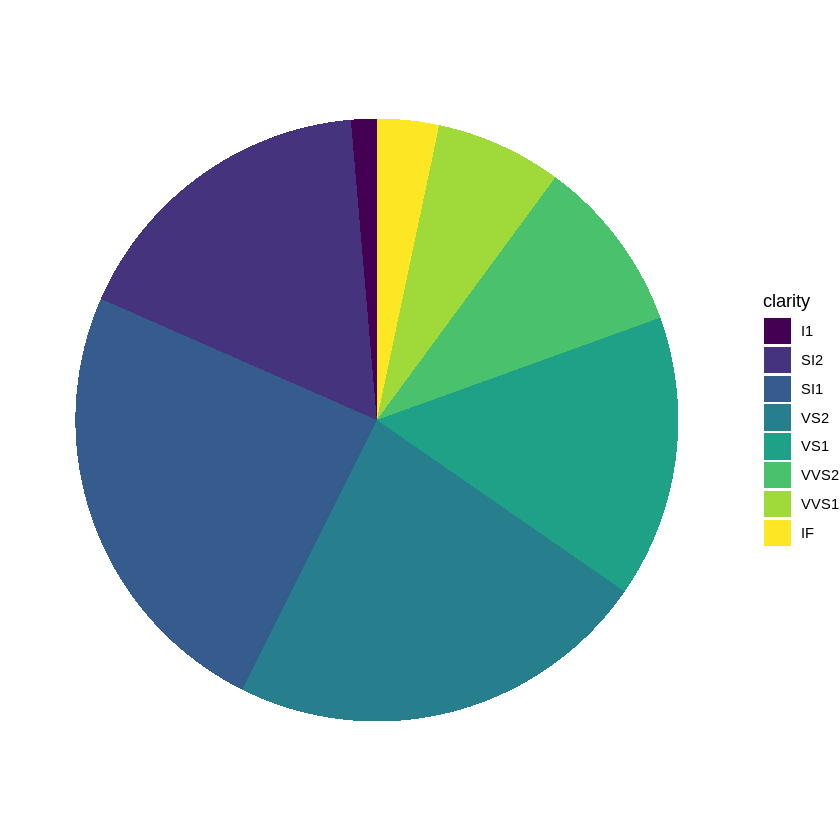

In [15]:
pie <- bar + coord_polar(theta = "y")  # use theta="y" to map height to angle

pie

## 9.7.2
coord_quickmap():
<ul>
<li>Purpose: This is a much faster, approximate coordinate system primarily used for displaying maps with a relatively small extent where distortion due to projection is not a major concern.</li>
<li>How it works: It sets the aspect ratio correctly for maps, but it does not perform a full map projection. Instead, it approximates a Mercator projection without transforming the underlying data. It treats latitude and longitude as Cartesian coordinates but adjusts their ratio to appear more map-like.</li>
<li>Best for: Global or large-scale maps where speed is more important than precise projection, or when the area of interest is not too large and is close to the equator. It's often suitable for data that is already in latitude/longitude coordinates.</li>
</ul>

coord_map():
<ul>
<li>Purpose: This is a more accurate, but computationally more intensive, coordinate system for maps that performs a full map projection.</li>
<li>How it works: It projects the data from spherical coordinates (latitude and longitude) onto a 2D plane using a specified map projection (e.g., Mercator, Albers, Lambert). This involves complex mathematical transformations of the data points.</li>
<li>Best for: Maps where accurate geographical representation and specific projections are crucial, especially for regions far from the equator, or when you need to compare areas or shapes accurately. You need to specify the projection and optionally parameters for the projection.</li>
</ul>

Installing package into ‘/usr/local/lib/R/site-library’
(as ‘lib’ is unspecified)


Attaching package: ‘maps’


The following object is masked from ‘package:purrr’:

    map




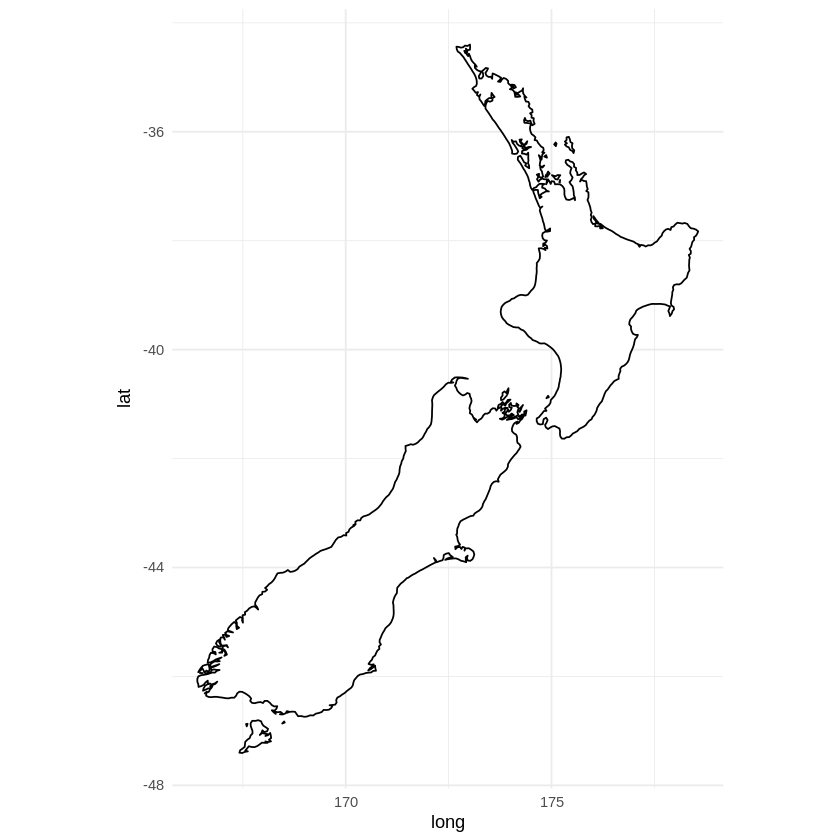

In [19]:
install.packages("maps")
library(maps)
nz <- map_data("nz")

ggplot(nz, aes(x = long, y = lat, group = group)) +
  geom_polygon(fill = "white", colour = "black") +
  coord_quickmap() +
  theme_minimal()

## 9.7.3

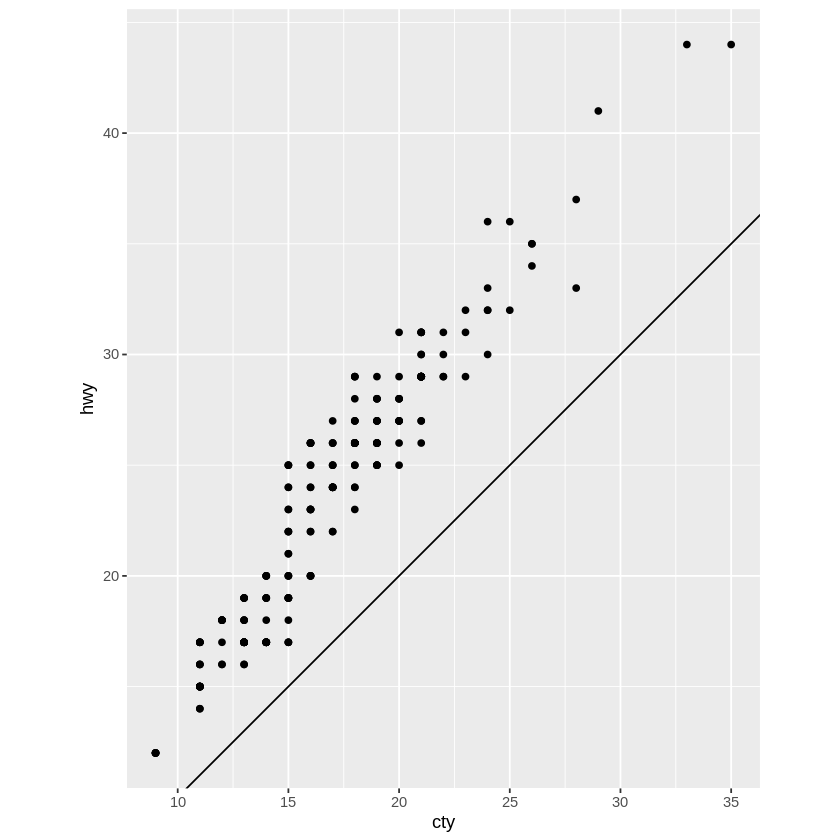

In [20]:
ggplot(data = mpg, mapping = aes(x = cty, y = hwy)) +
  geom_point() +
  geom_abline() +
  coord_fixed()

1. What does the plot tell you about the relationship between city and highway mpg?

The plot visualizes the relationship between cty (city miles per gallon) on the x-axis and hwy (highway miles per gallon) on the y-axis for the mpg dataset. You'll observe a positive correlation: as city MPG increases, highway MPG generally also increases. This is expected, as more fuel-efficient cars typically perform better in both city and highway conditions. The spread of the points also shows variability in this relationship across different car models.

2. Why is coord_fixed() important?

coord_fixed() is crucial in this plot because it ensures that the aspect ratio of the plot is fixed, meaning one unit on the x-axis has the same physical length as one unit on the y-axis. This is particularly important when geom_abline() is used with its default slope = 1.

Without coord_fixed(), the visual slope of the line added by geom_abline() might appear distorted depending on the default scaling of your plotting device. With coord_fixed(), a line with a slope of 1 will always appear as a true 45-degree diagonal line, allowing for an accurate visual comparison of the cty and hwy values relative to a perfect 1:1 ratio.

3. What does geom_abline() do?

geom_abline() adds a reference line to the plot. In this specific code, since no intercept or slope arguments are provided, it defaults to drawing a line with an intercept = 0 and a slope = 1. This effectively draws the line y = x.

This y = x line serves as a baseline: any points falling exactly on this line would have identical city and highway MPG values. Points above the line indicate cars with higher highway MPG than city MPG, while points below would indicate cars with lower highway MPG than city MPG. Given that cars are generally more fuel-efficient on the highway than in the city, you would typically expect most points to lie above this y = x line, demonstrating that hwy is usually greater than cty.